# **Сравнение регрессионных моделей на конкретной задаче. Интерпретация моделей. Статистический анализ линейной модели.**

**Источник данных:** `datasets::Theoph` (Pharmacokinetics of Theophylline)  
**Срез:** Subject == 1, Time >= 1  
**Фактор x:** Время (ч)  
**Отклик y:** Концентрация теофиллина в крови (мг/л)  
**Сравниваемые модели:** линейная, квадратичная, показательная  
**Прогнозное значение:** x* = 8.7250 (108% от среднего уровня фактора)

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Исходные данные
df_raw = pd.read_csv('Theoph.csv')
x = df_raw.loc[(df_raw['Subject'] == 1) & (df_raw['Time'] >= 1), 'Time'].values
y = df_raw.loc[(df_raw['Subject'] == 1) & (df_raw['Time'] >= 1), 'conc'].values

n = len(x)

# Таблица исходных данных
df = pd.DataFrame({'i': range(1, n+1), 'x (время, ч)': x, 'y (концентрация)': y})
print(df.to_string(index=False))
print(f"\nn = {n}")
print(f"x̄ = {x.mean():.4f}")
print(f"ȳ = {y.mean():.4f}")
print(f"x* = {x.mean() * 1.08:.4f}  (108% от среднего)")

 i  x (время, ч)  y (концентрация)
 1          1.12             10.50
 2          2.02              9.66
 3          3.82              8.58
 4          5.10              8.36
 5          7.03              7.47
 6          9.05              6.89
 7         12.12              5.94
 8         24.37              3.28

n = 8
x̄ = 8.0788
ȳ = 7.5850
x* = 8.7251  (108% от среднего)


## **4.1. Первичный анализ данных**

**Описание источника:**  
Набор данных `Theoph` содержит результаты фармакокинетического исследования теофиллина —
препарата, применяемого при бронхиальной астме. Измерялась концентрация вещества в крови
у 12 испытуемых в разные моменты времени после приёма дозы.  
Для работы взят срез: испытуемый №1, измерения начиная с 1-го часа после приёма
(фаза элиминации — когда концентрация уже снижается).

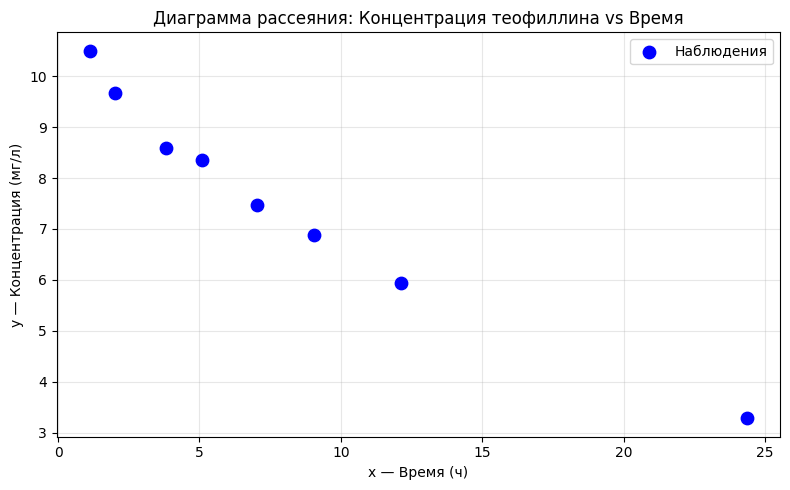

In [22]:
# Диаграмма рассеяния
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', s=80, zorder=5, label='Наблюдения')
plt.xlabel('x — Время (ч)')
plt.ylabel('y — Концентрация (мг/л)')
plt.title('Диаграмма рассеяния: Концентрация теофиллина vs Время')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### **Гипотеза о характере связи**

По диаграмме рассеяния прослеживается **монотонная убывающая** зависимость: чем больше
время после приёма препарата, тем ниже его концентрация в крови. Связь **отрицательная**.

Характер убывания нелинейный: при малых значениях x (1–5 ч) концентрация снижается быстро, при больших (12–24 ч) — медленнее. Кривая выпуклая, что
типично для **показательного (экспоненциального) убывания**.

**Предварительная гипотеза:** наиболее адекватной будет показательная модель вида
ŷ = a·e^(bx), поскольку именно такой вид описывает выведение препарата из организма
по кинетике первого порядка.

## **4.2. Построение регрессионных моделей**

### **Линейная модель: ŷ = a + b·x**

In [23]:
x_mean = x.mean()
y_mean = y.mean()

Sxx = np.sum((x - x_mean)**2)
Sxy = np.sum((x - x_mean) * (y - y_mean))

b_lin = Sxy / Sxx          # коэффициент наклона
a_lin = y_mean - b_lin * x_mean  # свободный член

y_pred = a_lin + b_lin * x   # прогнозные значения

print("ЛИНЕЙНАЯ МОДЕЛЬ")
print(f"a (свободный член) = {a_lin:.4f}")
print(f"b (наклон)         = {b_lin:.4f}")
print(f"\nУравнение: ŷ = {a_lin:.4f} + ({b_lin:.4f})·x")
print(f"         = {a_lin:.4f} − {abs(b_lin):.4f}·x")

# Качество модели
TSS = np.sum((y - y_mean)**2)
RSS = np.sum((y - y_pred)**2)
R2 = 1 - RSS / TSS
RMSE = np.sqrt(RSS / n)
MAPE = 100 * np.mean(np.abs((y - y_pred) / y))

print(f"\nR²   = {R2:.4f}")
print(f"RMSE = {RMSE:.4f}")
print(f"MAPE = {MAPE:.2f}%")

ЛИНЕЙНАЯ МОДЕЛЬ
a (свободный член) = 9.9670
b (наклон)         = -0.2949

Уравнение: ŷ = 9.9670 + (-0.2949)·x
         = 9.9670 − 0.2949·x

R²   = 0.9527
RMSE = 0.4621
MAPE = 6.24%


**Результаты линейной модели**

Уравнение: **ŷ = 9.9670 − 0.2949·x**

Коэффициент **b = −0.2949** означает, что с каждым дополнительным часом концентрация
теофиллина в среднем снижается на **0.295 мг/л**.
Коэффициент **a = 9.967** — теоретическая концентрация в момент x = 0 (начало отсчёта).

Качество модели: **R² = 0.953** — линейная модель объясняет 95.3% изменчивости
концентрации. RMSE = 0.462 мг/л, MAPE = 6.24%.

Несмотря на высокий R², значение MAPE = 6.24% указывает на то, что линейная модель не является оптимальной для данных с нелинейным характером убывания. Для более точного описания зависимости требуется нелинейная модель.

### **Квадратичная модель: ŷ = a + b·x + c·x²**

In [24]:
coeffs_quad = np.polyfit(x, y, deg=2)   # [c, b, a] — возвращает от старшей степени (мнк)
c_q, b_q, a_q = coeffs_quad

y_pred_quad = np.polyval(coeffs_quad, x)

print("КВАДРАТИЧНАЯ МОДЕЛЬ")
print(f"a = {a_q:.4f}")
print(f"b = {b_q:.4f}")
print(f"c = {c_q:.4f}")
print(f"\nУравнение: ŷ = {a_q:.4f} + ({b_q:.4f})·x + ({c_q:.4f})·x²")

RSS_quad = np.sum((y - y_pred_quad)**2)
R2_quad = 1 - RSS_quad / TSS
RMSE_quad = np.sqrt(RSS_quad / n)
MAPE_quad = 100 * np.mean(np.abs((y - y_pred_quad) / y))

print(f"\nR²   = {R2_quad:.4f}")
print(f"RMSE = {RMSE_quad:.4f}")
print(f"MAPE = {MAPE_quad:.2f}%")

КВАДРАТИЧНАЯ МОДЕЛЬ
a = 10.7457
b = -0.5117
c = 0.0085

Уравнение: ŷ = 10.7457 + (-0.5117)·x + (0.0085)·x²

R²   = 0.9928
RMSE = 0.1801
MAPE = 1.73%


**Результаты квадратичной модели**

Уравнение: **ŷ = 10.7457 − 0.5117·x + 0.0085·x²**

Коэффициент при x² положительный и очень малый (c = 0.0085), то есть парабола
слегка «выпуклая» снизу — кривая убывает быстро, потом замедляется.

Качество значительно улучшилось по сравнению с линейной: **R² = 0.9928**, RMSE = 0.180 мг/л,
MAPE = 1.73%. Модель хорошо описывает данные, однако квадратичная форма не имеет
физического обоснования для данной задачи — теоретически при очень больших x она
могла бы начать расти, что бессмысленно для концентрации вещества.

### **Показательная модель: ŷ = a·e^(b·x)**

**Линеаризация:** логарифмируем обе части → ln(ŷ) = ln(a) + b·x  
Обозначим Y = ln(y), A = ln(a) → получаем линейную модель Y = A + b·x,  
которую оцениваем обычным МНК, а потом возвращаемся к исходным переменным: a = e^A.

In [25]:
ln_y = np.log(y)   # логарифмируем y

# МНК для линеаризованной модели
Sxx_exp = np.sum((x - x_mean)**2)
Sxy_exp = np.sum((x - x_mean) * (ln_y - ln_y.mean()))

b_exp = Sxy_exp / Sxx_exp
A_exp = ln_y.mean() - b_exp * x_mean
a_exp = np.exp(A_exp)  # возврат к исходному масштабу

y_pred_exp = a_exp * np.exp(b_exp * x)

print("ПОКАЗАТЕЛЬНАЯ МОДЕЛЬ")
print(f"Линеаризованный вид: ln(y) = {A_exp:.4f} + ({b_exp:.4f})·x")
print(f"\na = e^{A_exp:.4f} = {a_exp:.4f}")
print(f"b = {b_exp:.4f}")
print(f"\nУравнение: ŷ = {a_exp:.4f} · e^({b_exp:.4f}·x)")

RSS_exp = np.sum((y - y_pred_exp)**2)
R2_exp = 1 - RSS_exp / TSS
RMSE_exp = np.sqrt(RSS_exp / n)
MAPE_exp = 100 * np.mean(np.abs((y - y_pred_exp) / y))

print(f"\nR²   = {R2_exp:.4f}")
print(f"RMSE = {RMSE_exp:.4f}")
print(f"MAPE = {MAPE_exp:.2f}%")

ПОКАЗАТЕЛЬНАЯ МОДЕЛЬ
Линеаризованный вид: ln(y) = 2.3685 + (-0.0487)·x

a = e^2.3685 = 10.6809
b = -0.0487

Уравнение: ŷ = 10.6809 · e^(-0.0487·x)

R²   = 0.9931
RMSE = 0.1760
MAPE = 1.27%


**Результаты показательной модели**

**Линеаризация:** логарифмируем обе части: ln(y) = ln(a) + b·x
Оценка МНК в логарифмическом пространстве дала: ln(y) = 2.3685 − 0.0487·x

Возврат к исходному масштабу: a = e^2.3685 = **10.6809**, b = **−0.0487**

Уравнение: **ŷ = 10.6809 · e^(−0.0487·x)**

Коэффициент **b = −0.0487** — константа скорости элиминации: за каждый час концентрация
убывает примерно на **4.76%** от текущего уровня (e^(−0.0487) ≈ 0.9524).

Качество: **R² = 0.9931**, RMSE = 0.176 мг/л, MAPE = **1.27%** — лучший результат среди
трёх моделей. Модель физически обоснована и практически точна.

## **4.3. Сравнение моделей и графики**

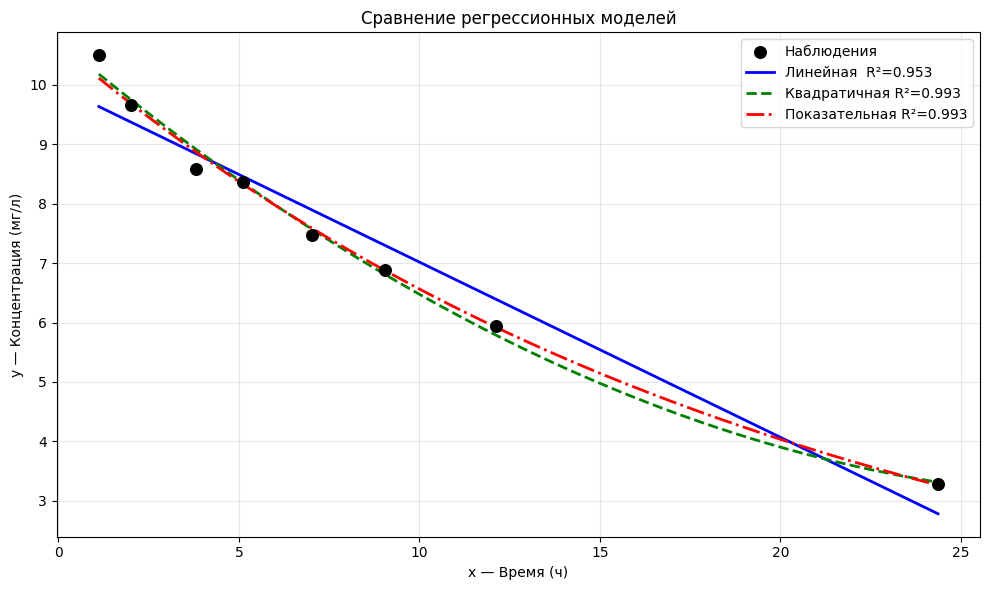


СРАВНЕНИЕ МОДЕЛЕЙ
       Модель     R²   RMSE  MAPE (%)
     Линейная 0.9527 0.4621      6.24
 Квадратичная 0.9928 0.1801      1.73
Показательная 0.9931 0.1760      1.27

Лучшая модель по R²: Показательная


In [26]:
x_smooth = np.linspace(x.min(), x.max(), 300)

y_smooth_lin  = a_lin + b_lin * x_smooth
y_smooth_quad = np.polyval(coeffs_quad, x_smooth)
y_smooth_exp  = a_exp * np.exp(b_exp * x_smooth)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color='black', s=70, zorder=5, label='Наблюдения')
plt.plot(x_smooth, y_smooth_lin,  'b-',  lw=2, label=f'Линейная  R²={R2:.3f}')
plt.plot(x_smooth, y_smooth_quad, 'g--', lw=2, label=f'Квадратичная R²={R2_quad:.3f}')
plt.plot(x_smooth, y_smooth_exp,  'r-.',  lw=2, label=f'Показательная R²={R2_exp:.3f}')

plt.xlabel('x — Время (ч)')
plt.ylabel('y — Концентрация (мг/л)')
plt.title('Сравнение регрессионных моделей')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    'Модель':   ['Линейная', 'Квадратичная', 'Показательная'],
    'R²':       [round(R2, 4),   round(R2_quad, 4),  round(R2_exp, 4)],
    'RMSE':     [round(RMSE, 4), round(RMSE_quad, 4), round(RMSE_exp, 4)],
    'MAPE (%)': [round(MAPE, 2), round(MAPE_quad, 2), round(MAPE_exp, 2)]
})
print("\nСРАВНЕНИЕ МОДЕЛЕЙ")
print(comparison.to_string(index=False))

best_idx = comparison['R²'].idxmax()
print(f"\nЛучшая модель по R²: {comparison.loc[best_idx, 'Модель']}")

**Сравнение трёх моделей**

| Модель        | R²     | RMSE   | MAPE   |
|---------------|--------|--------|--------|
| Линейная      | 0.9527 | 0.4621 | 6.24%  |
| Квадратичная  | 0.9928 | 0.1801 | 1.73%  |
| Показательная | **0.9931** | **0.1760** | **1.27%** |

**Вывод:** квадратичная и показательная модели значительно превосходят линейную по всем
критериям. Между собой они очень близки по R² и RMSE, однако показательная модель
предпочтительнее по двум причинам:

1. **MAPE = 1.27%** — минимальная средняя ошибка аппроксимации (отличный результат).
2. **Физическая осмысленность** — экспоненциальное убывание соответствует кинетике
   первого порядка, описывающей выведение препарата из организма. Квадратичная модель
   такого обоснования не имеет.

На графике видно, что показательная и квадратичная кривые практически совпадают и
плотно облегают точки наблюдений, тогда как линейная систематически отклоняется
в крайних зонах (переоценивает концентрацию при малых x и при больших x).

## **4.4. Подробный статистический анализ линейной модели**

ПОДРОБНЫЙ АНАЛИЗ ЛИНЕЙНОЙ МОДЕЛИ

Таблица остатков:
 i     x     y      ŷ   e=y-ŷ     e²
 1  1.12 10.50 9.6368  0.8632 0.7451
 2  2.02  9.66 9.3714  0.2886 0.0833
 3  3.82  8.58 8.8407 -0.2607 0.0680
 4  5.10  8.36 8.4633 -0.1033 0.0107
 5  7.03  7.47 7.8942 -0.4242 0.1800
 6  9.05  6.89 7.2986 -0.4086 0.1670
 7 12.12  5.94 6.3934 -0.4534 0.2056
 8 24.37  3.28 2.7815  0.4985 0.2485

RSS = Σe² = 1.7081
s²  = RSS/(n-2) = 1.7081/6 = 0.2847
s   = √s²       = 0.5336

Стандартные ошибки
SE(b) = s/√Sxx = 0.0268
SE(a) = s·√(1/n + x̄²/Sxx) = 0.2873

t-критическое значение
t(1-α/2; n-2) = t(0.975; 6) = 2.4469

95% Доверительные интервалы
b: [-0.3605;  -0.2292]
a: [9.2642;  10.6699]

Проверка гипотезы H₀: b = 0
t_набл = b/SE(b) = -0.2949/0.0268 = -10.9960
t_крит = 2.4469
p-value = 0.000034
|t_набл| = 10.9960 > t_крит = 2.4469
=> H₀ ОТВЕРГАЕТСЯ: связь статистически ЗНАЧИМА (α = 0.05)


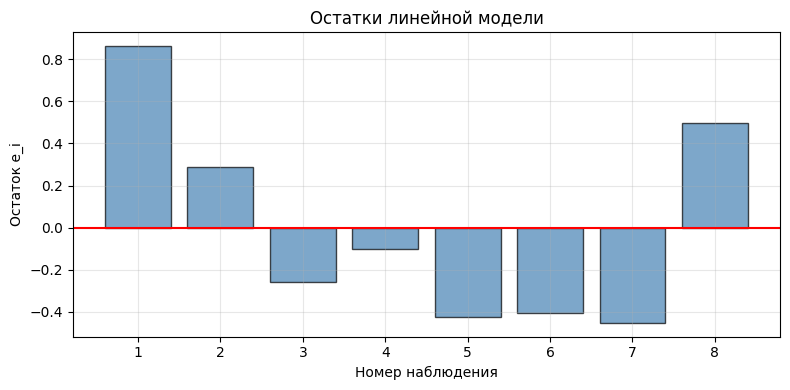

In [27]:
residuals = y - y_pred     # остатки e_i = y_i - ŷ_i
RSS_lin_val = np.sum(residuals**2)   # остаточная сумма квадратов
s2 = RSS_lin_val / (n - 2)          # несмещённая оценка дисперсии
s  = np.sqrt(s2)                    # стандартное отклонение ошибки

# Стандартные ошибки коэффициентов
SE_b = s / np.sqrt(Sxx)
SE_a = s * np.sqrt(1/n + x_mean**2 / Sxx)

# t-квантиль для 95% ДИ (двусторонний, df = n-2 = 6)
alpha = 0.05
df_resid = n - 2
t_crit = stats.t.ppf(1 - alpha/2, df=df_resid)
5
# Доверительные интервалы
CI_b = (b_lin - t_crit * SE_b, b_lin + t_crit * SE_b)
CI_a = (a_lin - t_crit * SE_a, a_lin + t_crit * SE_a)

# t-статистика для проверки H0: b = 0
t_obs = b_lin / SE_b
p_value = 2 * stats.t.sf(abs(t_obs), df=df_resid)

print("ПОДРОБНЫЙ АНАЛИЗ ЛИНЕЙНОЙ МОДЕЛИ\n")

# Таблица остатков
print("Таблица остатков:")
resid_df = pd.DataFrame({
    'i': range(1, n+1),
    'x':   np.round(x, 2),
    'y':   np.round(y, 2),
    'ŷ':   np.round(y_pred, 4),
    'e=y-ŷ': np.round(residuals, 4),
    'e²':  np.round(residuals**2, 4)
})
print(resid_df.to_string(index=False))

print(f"\nRSS = Σe² = {RSS_lin_val:.4f}")
print(f"s²  = RSS/(n-2) = {RSS_lin_val:.4f}/{n-2} = {s2:.4f}")
print(f"s   = √s²       = {s:.4f}")

print(f"\nСтандартные ошибки")
print(f"SE(b) = s/√Sxx = {SE_b:.4f}")
print(f"SE(a) = s·√(1/n + x̄²/Sxx) = {SE_a:.4f}")

print(f"\nt-критическое значение")
print(f"t(1-α/2; n-2) = t(0.975; {df_resid}) = {t_crit:.4f}")

print(f"\n95% Доверительные интервалы")
print(f"b: [{CI_b[0]:.4f};  {CI_b[1]:.4f}]")
print(f"a: [{CI_a[0]:.4f};  {CI_a[1]:.4f}]")

print(f"\nПроверка гипотезы H₀: b = 0")
print(f"t_набл = b/SE(b) = {b_lin:.4f}/{SE_b:.4f} = {t_obs:.4f}")
print(f"t_крит = {t_crit:.4f}")
print(f"p-value = {p_value:.6f}")
if abs(t_obs) > t_crit:
    print(f"|t_набл| = {abs(t_obs):.4f} > t_крит = {t_crit:.4f}")
    print("=> H₀ ОТВЕРГАЕТСЯ: связь статистически ЗНАЧИМА (α = 0.05)")
else:
    print("=> H₀ не отвергается: связь статистически незначима")

# График остатков
plt.figure(figsize=(8, 4))
plt.bar(range(1, n+1), residuals, color='steelblue', edgecolor='black', alpha=0.7)
plt.axhline(0, color='red', lw=1.5)
plt.xlabel('Номер наблюдения')
plt.ylabel('Остаток e_i')
plt.title('Остатки линейной модели')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Интерпретация статистического анализа линейной модели**

**Остатки и дисперсия ошибки:**
RSS = 1.7081 — сумма квадратов отклонений реальных значений от прямой.
s² = 1.7081 / 6 = **0.2847** — оценка дисперсии случайной ошибки модели.
s = **0.534 мг/л** — типичная величина ошибки предсказания линейной модели.

На графике остатков заметен характерный паттерн: наблюдения 1–2 и 8 дают
положительные остатки (модель недооценивает), наблюдения 5–7 — отрицательные
(модель переоценивает). Это подтверждает нелинейность зависимости, которую
прямая не улавливает.

**Доверительные интервалы (95%):**
- для b: [−0.3605; −0.2292] — ноль в интервал **не входит**
- для a: [9.2642; 10.6699]

**Проверка гипотезы H₀: b = 0**
t_набл = −10.996, t_крит = 2.447, p-value = 0.000034

|t_набл| = 10.996 **>>** t_крит = 2.447 → **H₀ отвергается**.

**Вывод:** зависимость концентрации от времени статистически значима на уровне α = 0.05
(и даже намного ниже — p < 0.0001). Коэффициент наклона значимо отличается от нуля,
то есть время действительно является значимым фактором, объясняющим изменение
концентрации теофиллина.

## **4.5. Прогноз при $x^{*}$ = 8.7250**

In [28]:
x_star = 8.7250

y_hat_lin  = a_lin + b_lin * x_star
y_hat_quad = np.polyval(coeffs_quad, x_star)
y_hat_exp  = a_exp * np.exp(b_exp * x_star)

print(f"ПРОГНОЗ ПРИ x* = {x_star}\n")
print(f"Линейная модель:      ŷ = {y_hat_lin:.4f} мг/л")
print(f"Квадратичная модель:  ŷ = {y_hat_quad:.4f} мг/л")
print(f"Показательная модель: ŷ = {y_hat_exp:.4f} мг/л")

print(f"""
Основная модель для прогноза: Показательная (наибольший R²).
При времени {x_star} ч после приёма препарата ожидаемая концентрация
теофиллина в крови испытуемого составит примерно {y_hat_exp:.2f} мг/л.
""")

ПРОГНОЗ ПРИ x* = 8.725

Линейная модель:      ŷ = 7.3945 мг/л
Квадратичная модель:  ŷ = 6.9267 мг/л
Показательная модель: ŷ = 6.9860 мг/л

Основная модель для прогноза: Показательная (наибольший R²).
При времени 8.725 ч после приёма препарата ожидаемая концентрация
теофиллина в крови испытуемого составит примерно 6.99 мг/л.



**Интерпретация прогноза**

При x* = 8.7251 ч (108% от среднего уровня фактора) три модели дают следующие прогнозы:

| Модель        | Прогноз ŷ(x*) |
|---------------|---------------|
| Линейная      | 7.3945 мг/л   |
| Квадратичная  | 6.9267 мг/л   |
| Показательная | **6.9860 мг/л** |

Для прогноза выбрана **показательная модель** как наилучшая по всем критериям качества.

**Содержательная интерпретация:**
Через 8 часов 44 минуты после приёма теофиллина испытуемым ожидаемая концентрация
препарата в его крови составит примерно **6.99 мг/л**. Это значение укладывается в
общую тенденцию постепенного снижения концентрации: за примерно 8.7 часов
концентрация упала с начальных ~10.7 мг/л почти вдвое, что соответствует
характерному периоду полувыведения теофиллина у данного испытуемого.

## **4.6. Итоговый вывод**

В работе исследовалась зависимость концентрации теофиллина в крови испытуемого №1
от времени после приёма препарата. Данные получены из реального набора `datasets::Theoph`,
срез: Subject = 1, Time ≥ 1 ч (фаза элиминации).

Были построены три регрессионные модели. Линейная модель (R² = 0.953) приемлемо
описывает общий тренд, но систематически ошибается в крайних зонах из-за нелинейности
данных. Квадратичная (R² = 0.993) и показательная (R² = 0.993) модели близки по
точности, однако **показательная модель** в итоге стала предпочтительной: она имеет
минимальную среднюю ошибку аппроксимации (MAPE = 1.27%) и физически обоснована —
экспоненциальное убывание соответствует кинетике первого порядка выведения препарата.

Статистический анализ линейной модели подтвердил значимость зависимости: t-статистика
(|t| = 10.996) значительно превышает критическое значение (2.447), p-value < 0.0001,
доверительный интервал для коэффициента наклона не содержит ноль.

Прогноз по показательной модели при x* = 8.725 ч: **ŷ ≈ 6.99 мг/л**. Связь
отрицательная и статистически высоко значимая: с течением времени концентрация
теофиллина в крови закономерно снижается по экспоненциальному закону.